In [3]:
##########################
# RDE NUMERICAL SOLUTION #
##########################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np 

In [4]:
kappa1 = 0.7
theta1 = 0.5
sigma1 = 0.3
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.6
theta2 = 0.4
sigma2 = 0.2
b2 = kappa2*theta2
epsilon2 = -kappa2

kappa3 = 0.5
theta3 = 0.3
sigma3 = 0.1
b3 = kappa3*theta3
epsilon3 = -kappa3

def funVasicek(t, U):
    alpha, beta1, beta2, beta3 = U
    return [b1*beta1+b2*beta2+b3*beta3+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2+(1/2)*sigma3**2*beta3**2, epsilon1*beta1-1, epsilon2*beta2-1, epsilon3*beta3-1]

U_0 = [0, 0, 0, 0]
t_pts = np.linspace(0, 10, 11)
resultVasicek = solve_ivp(funVasicek, (0, 10), U_0, t_eval=t_pts, method='RK45')

resultVasicek

  message: 'The solver successfully reached the end of the integration interval.'
     nfev: 68
     njev: 0
      nlu: 0
      sol: None
   status: 0
  success: True
        t: array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])
 t_events: None
        y: array([[ 0.        , -0.28876993, -0.93859246, -1.76705582, -2.68777214,
        -3.65883341, -4.65652863, -5.66986098, -6.6910216 , -7.71748579,
        -8.74645751],
       [ 0.        , -0.71926402, -1.07637703, -1.25347091, -1.34190836,
        -1.38521044, -1.40728137, -1.41764631, -1.4234124 , -1.42577849,
        -1.42707126],
       [ 0.        , -0.75203414, -1.16473191, -1.39108481, -1.51561787,
        -1.5835574 , -1.62124396, -1.64146864, -1.65308329, -1.6590024 ,
        -1.66235591],
       [ 0.        , -0.78696415, -1.26427238, -1.55370258, -1.72942179,
        -1.83576464, -1.90051605, -1.93947839, -1.96349425, -1.97768816,
        -1.98638188]])
 y_events: None

In [5]:
###########################
# SWAPTION EXERCISE BOUND #
###########################

# Consider swaption given by t=0, S=5, T=10 and yearly cashflows in between

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np

In [6]:
#ATMF strike Vasicek + sanity check
# r0 = [0.5, 0.5, 0.5]

VasPtT1 = np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*0.05+resultVasicek.y[2,1]*0.05+resultVasicek.y[3,1]*0.05)
VasPtT2 = np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*0.05+resultVasicek.y[2,2]*0.05+resultVasicek.y[3,2]*0.05)
VasPtT3 = np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*0.05+resultVasicek.y[2,3]*0.05+resultVasicek.y[3,3]*0.05)
VasPtT4 = np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*0.05+resultVasicek.y[2,4]*0.05+resultVasicek.y[3,4]*0.05)
VasPtS = np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*0.05+resultVasicek.y[2,5]*0.05+resultVasicek.y[3,5]*0.05)
VasPtT6 = np.exp(resultVasicek.y[0,6]+resultVasicek.y[1,6]*0.05+resultVasicek.y[2,6]*0.05+resultVasicek.y[3,6]*0.05)
VasPtT7 = np.exp(resultVasicek.y[0,7]+resultVasicek.y[1,7]*0.05+resultVasicek.y[2,7]*0.05+resultVasicek.y[3,7]*0.05)
VasPtT8 = np.exp(resultVasicek.y[0,8]+resultVasicek.y[1,8]*0.05+resultVasicek.y[2,8]*0.05+resultVasicek.y[3,8]*0.05)
VasPtT9 = np.exp(resultVasicek.y[0,9]+resultVasicek.y[1,9]*0.05+resultVasicek.y[2,9]*0.05+resultVasicek.y[3,9]*0.05)
VasPtT = np.exp(resultVasicek.y[0,10]+resultVasicek.y[1,10]*0.05+resultVasicek.y[2,10]*0.05+resultVasicek.y[3,10]*0.05)

VasATMFSwapK = (VasPtS - VasPtT)/(VasPtT6 + VasPtT7 + VasPtT8 + VasPtT9 + VasPtT)
KVasicek = VasATMFSwapK
VasATMFSwapK, VasPtS-KVasicek*VasPtT6-KVasicek*VasPtT7-KVasicek*VasPtT8-KVasicek*VasPtT9-(1+KVasicek)*VasPtT

(1.7443613107952745, 2.656295322589486e-18)

In [5]:
###################################
# SIMULATION a.k.a. "TRUE PRICES" #
###################################

import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
from IPython.display import display

In [6]:
def VasicekProcess(kappa1, kappa2, kappa3, theta1, theta2, theta3, sigma1, sigma2, sigma3, r0, T, dt, rho):
    N = int(T / dt)
    W_1 = [r0]
    W_2 = [r0]
    W_3 = [r0]
    
    for i in range(N):
        Z1 = np.random.normal(scale = np.sqrt(dt))
        Z2 = np.random.normal(scale = np.sqrt(dt))
        Z3 = rho * Z1 + np.sqrt(1 - rho**2) * Z2
        Z4 = np.random.normal(scale = np.sqrt(dt))
        r_new1 = W_1[i] + kappa1 * (theta1 - W_1[i]) * dt + sigma1 * Z1
        r_new2 = W_2[i] + kappa2 * (theta2 - W_2[i]) * dt + sigma2 * Z3
        r_new3 = W_3[i] + kappa3 * (theta3 - W_3[i]) * dt + sigma3 * Z4
        W_1.append(r_new1)
        W_2.append(r_new2)
        W_3.append(r_new3)
        
    return [W_1, W_2, W_3]

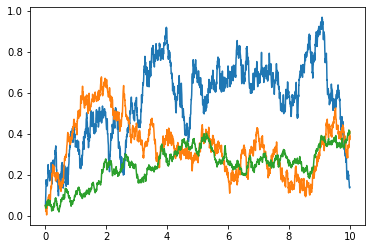

In [14]:
VasicekList = VasicekProcess(0.7,0.6,0.5,0.5,0.4,0.3,0.3,0.2,0.1,0.05,10,0.005,0)
x=np.linspace(0, 10, 2001)
plt.plot(x,VasicekList[0])
plt.plot(x,VasicekList[1])
plt.plot(x,VasicekList[2])
plt.show()

In [20]:
#Sanity check Vasicek sim price
Nsims = 1000
listVasicektest = []
for i in range(Nsims):
    VasicekPath = VasicekProcess(0.7,0.6,0.5,0.5,0.4,0.3,0.3,0.2,0.1,0.05,10,0.005,0)
    VasicekZCB = np.exp(sum(-np.trapz(VasicekPath))*0.005).tolist()
    listVasicektest.append(VasicekZCB)
np.mean(listVasicektest), np.exp(resultVasicek.y[0,10]+resultVasicek.y[1,10]*0.05+resultVasicek.y[2,10]*0.05+resultVasicek.y[3,10]*0.05)

(0.00011497894450343343, 0.00012337920656669968)

In [21]:
#Sanity check Vasicek sim price expiry T = S = 5 instead of expiry 10
Nsims = 1000
listVasicektest = []
for i in range(Nsims):
    VasicekPath = VasicekProcess(0.7,0.6,0.5,0.5,0.4,0.3,0.3,0.2,0.1,0.05,10,0.005,0)
    VasicekZCB = np.exp(-np.trapz(VasicekPath[0][0:1000])*0.005-np.trapz(VasicekPath[1][0:1000])*0.005-np.trapz(VasicekPath[2][0:1000])*0.005).tolist()
    listVasicektest.append(VasicekZCB)
np.mean(listVasicektest), np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*0.05+resultVasicek.y[2,5]*0.05+resultVasicek.y[3,5]*0.05)

(0.02090796429001052, 0.02026094717803384)

In [23]:
NsimsVasicek = 10000
listVasicekPaths = []
listMaximizer = []
listVasicekSwaption = []
for i in range(NsimsVasicek):
    VasicekPath = VasicekProcess(0.7,0.6,0.5,0.5,0.4,0.3,0.3,0.2,0.1,0.05,10,0.005,0)
    listVasicekPaths.append(VasicekPath)
for i in range(NsimsVasicek-1):
    VasicekZCB6 = np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*listVasicekPaths[i][0][1000]+resultVasicek.y[2,1]*listVasicekPaths[i][1][1000]+resultVasicek.y[3,1]*listVasicekPaths[i][2][1000])
    VasicekZCB7 = np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*listVasicekPaths[i][0][1000]+resultVasicek.y[2,2]*listVasicekPaths[i][1][1000]+resultVasicek.y[3,2]*listVasicekPaths[i][2][1000])
    VasicekZCB8 = np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*listVasicekPaths[i][0][1000]+resultVasicek.y[2,3]*listVasicekPaths[i][1][1000]+resultVasicek.y[3,3]*listVasicekPaths[i][2][1000])
    VasicekZCB9 = np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*listVasicekPaths[i][0][1000]+resultVasicek.y[2,4]*listVasicekPaths[i][1][1000]+resultVasicek.y[3,4]*listVasicekPaths[i][2][1000])
    VasicekZCB10 = np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*listVasicekPaths[i][0][1000]+resultVasicek.y[2,5]*listVasicekPaths[i][1][1000]+resultVasicek.y[3,5]*listVasicekPaths[i][2][1000])
    Maximizer = max(1-KVasicek*VasicekZCB6-KVasicek*VasicekZCB7-KVasicek*VasicekZCB8-KVasicek*VasicekZCB9-(1+KVasicek)*VasicekZCB10,0)
    listMaximizer.append(Maximizer)
for i in range(NsimsVasicek-1):
    VasicekSwaption = listMaximizer[i]*np.exp(-np.trapz(listVasicekPaths[i][0][0:1000])/200-np.trapz(listVasicekPaths[i][1][0:1000])/200-np.trapz(listVasicekPaths[i][2][0:1000])/200).tolist()
    listVasicekSwaption.append(VasicekSwaption)
VasicekSwaptionPriceSim = np.mean(listVasicekSwaption)
VasicekSwaptionPriceSim

0.0024194609576342965

In [7]:
#################################################
# FETCH QUANTILES FROM RESPECTIVE DISTRIBUTIONS #
#################################################

from scipy.stats import norm
from scipy.linalg import lstsq
import statsmodels.api as sm
import numpy as np

In [8]:
#Vasicek 1st factor distr.

r0 = 0.05
expiryT = 5
kappa1 = 0.7
theta1 = 0.5
sigma1 = 0.3
EV1 = r0*np.exp(-kappa1*expiryT)+theta1*(1-np.exp(-kappa1*expiryT))
Var1 = (sigma1**2/kappa1)*(1-np.exp(-2*kappa1*expiryT))
lowerquantile1 = norm.ppf((1-0.9545)/2, loc=EV1, scale=Var1)
upperquantile1 = norm.ppf((1+0.9545)/2, loc=EV1, scale=Var1)

Var1, (lowerquantile1, EV1, upperquantile1)

(0.12845418660442873,
 (0.22950249032196351, 0.4864111774599567, 0.7433198645979497))

In [9]:
#Vasicek 2nd factor distr.

r0 = 0.05
expiryT = 5
kappa2 = 0.6
theta2 = 0.4
sigma2 = 0.2
EV2 = r0*np.exp(-kappa2*expiryT)+theta2*(1-np.exp(-kappa2*expiryT))
Var2 = (sigma2**2/kappa2)*(1-np.exp(-2*kappa2*expiryT))
lowerquantile2 = norm.ppf((1-0.9545)/2, loc=EV2, scale=Var2)
upperquantile2 = norm.ppf((1+0.9545)/2, loc=EV2, scale=Var2)

Var2, (lowerquantile2, EV2, upperquantile2)

(0.06650141652155558,
 (0.249571530505351, 0.38257452607124764, 0.5155775216371442))

In [10]:
#Vasicek 3rd factor distr.

r0 = 0.05
expiryT = 5
kappa3 = 0.5
theta3 = 0.3
sigma3 = 0.1
EV3 = r0*np.exp(-kappa3*expiryT)+theta3*(1-np.exp(-kappa3*expiryT))
Var3 = (sigma3**2/kappa3)*(1-np.exp(-2*kappa3*expiryT))
lowerquantile3 = norm.ppf((1-0.9545)/2, loc=EV3, scale=Var3)
upperquantile3 = norm.ppf((1+0.9545)/2, loc=EV3, scale=Var3)

Var3, (lowerquantile3, EV3, upperquantile3)

(0.019865241060018295,
 (0.23974821967533397, 0.2794787503440253, 0.3192092810127166))

In [29]:
#Sanity check against sim. Seems fine comparing means

r1Ssimlist = []
r2Ssimlist = []
r3Ssimlist = []
for i in range(Nsims-1):
    r1Ssim = listVasicekPaths[i][0][1000]
    r1Ssimlist.append(r1Ssim)
for i in range(Nsims-1):
    r2Ssim = listVasicekPaths[i][1][1000]
    r2Ssimlist.append(r2Ssim)
for i in range(Nsims-1):
    r3Ssim = listVasicekPaths[i][2][1000]
    r3Ssimlist.append(r3Ssim)
np.mean(r1Ssimlist), np.mean(r2Ssimlist), np.mean(r3Ssimlist)

(0.49378173884963156, 0.38601615986456644, 0.28055314456621333)

In [15]:
# Solve P(x)-1=0 <=> P(x)=1

VasEnd1ExerciseBound = lambda Y1S1 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S1+resultVasicek.y[2,1]*lowerquantile2+resultVasicek.y[3,1]*lowerquantile3)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S1+resultVasicek.y[2,2]*lowerquantile2+resultVasicek.y[3,2]*lowerquantile3)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S1+resultVasicek.y[2,3]*lowerquantile2+resultVasicek.y[3,3]*lowerquantile3)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S1+resultVasicek.y[2,4]*lowerquantile2+resultVasicek.y[3,4]*lowerquantile3)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S1+resultVasicek.y[2,5]*lowerquantile2+resultVasicek.y[3,5]*lowerquantile3)-1
VasY1S1_init_guess = 0.2
VasSolY1S1 = fsolve(VasEnd1ExerciseBound, VasY1S1_init_guess)

VasEnd2ExerciseBound = lambda Y1S2 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S2+resultVasicek.y[2,1]*lowerquantile2+resultVasicek.y[3,1]*upperquantile3)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S2+resultVasicek.y[2,2]*lowerquantile2+resultVasicek.y[3,2]*upperquantile3)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S2+resultVasicek.y[2,3]*lowerquantile2+resultVasicek.y[3,3]*upperquantile3)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S2+resultVasicek.y[2,4]*lowerquantile2+resultVasicek.y[3,4]*upperquantile3)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S2+resultVasicek.y[2,5]*lowerquantile2+resultVasicek.y[3,5]*upperquantile3)-1
VasY1S2_init_guess = 0.2
VasSolY1S2 = fsolve(VasEnd2ExerciseBound, VasY1S2_init_guess)

VasEnd3ExerciseBound = lambda Y1S3 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S3+resultVasicek.y[2,1]*upperquantile2+resultVasicek.y[3,1]*lowerquantile3)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S3+resultVasicek.y[2,2]*upperquantile2+resultVasicek.y[3,2]*lowerquantile3)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S3+resultVasicek.y[2,3]*lowerquantile2+resultVasicek.y[3,3]*lowerquantile3)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S3+resultVasicek.y[2,4]*upperquantile2+resultVasicek.y[3,4]*lowerquantile3)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S3+resultVasicek.y[2,5]*upperquantile2+resultVasicek.y[3,5]*lowerquantile3)-1
VasY1S3_init_guess = 0.2
VasSolY1S3 = fsolve(VasEnd3ExerciseBound, VasY1S3_init_guess)

VasEnd4ExerciseBound = lambda Y1S4 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S4+resultVasicek.y[2,1]*upperquantile2+resultVasicek.y[3,1]*upperquantile3)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S4+resultVasicek.y[2,2]*upperquantile2+resultVasicek.y[3,2]*upperquantile3)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S4+resultVasicek.y[2,3]*upperquantile2+resultVasicek.y[3,3]*upperquantile3)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S4+resultVasicek.y[2,4]*upperquantile2+resultVasicek.y[3,4]*upperquantile3)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S4+resultVasicek.y[2,5]*upperquantile2+resultVasicek.y[3,5]*upperquantile3)-1
VasY1S4_init_guess = 0.2
VasSolY1S4 = fsolve(VasEnd4ExerciseBound, VasY1S4_init_guess)

VasSolY1S1[0], VasSolY1S2[0], VasSolY1S3[0], VasSolY1S4[0]

(0.4607552388213342,
 0.3695132640044036,
 0.21623639347846219,
 0.0850610109667013)

In [ ]:
# so 4 points of dimension 3, and they become:
#(VasSolY1S1[0], lowerquantile2, lowerquantile3)
#(VasSolY1S2[0], lowerquantile2, upperquantile3)
#(VasSolY1S3[0], upperquantile2, lowerquantile3)
#(VasSolY1S4[0], upperquantile2, upperquantile3)

#So sketch the regression model like follows : VasSolY1SX = b*Xquantile2 + c*Xquantile3 + a

In [16]:
# OLS method in scipy package

y = np.array([VasSolY1S1[0], VasSolY1S2[0], VasSolY1S3[0], VasSolY1S4[0]])
M = np.array([[1, lowerquantile2, lowerquantile3],
              [1, lowerquantile2, upperquantile3],
              [1, upperquantile2, lowerquantile3],
              [1, upperquantile2, upperquantile3]])

In [31]:
coefVas3, res, rnk, s = lstsq(M, y)
coefVas3, res, rnk, s

(array([ 1.05442007, -0.99428418, -1.39953679]),
 0.0003986692625303898,
 3,
 array([2.21514224, 0.24950822, 0.0764873 ]))

In [35]:
#sanity check. holds reasonably well, with reasonably small residues
(coefVas3[1]*lowerquantile2+coefVas3[2]*lowerquantile3+coefVas3[0], coefVas3[1]*lowerquantile2+coefVas3[2]*upperquantile3+coefVas3[0], coefVas3[1]*upperquantile2+coefVas3[2]*lowerquantile3+coefVas3[0], coefVas3[1]*upperquantile2+coefVas3[2]*upperquantile3+coefVas3[0]),(VasSolY1S1[0], VasSolY1S2[0], VasSolY1S3[0], VasSolY1S4[0])

((0.47073859074504165,
  0.35952991208069607,
  0.20625304155475455,
  0.09504436289040907),
 (0.4607552388213342,
  0.3695132640044036,
  0.21623639347846219,
  0.0850610109667013))

In [ ]:
# Remember the above model is Y1 = b*Y2 + c*Y3 + a
# but we need Y1-b*Y2-c*Y3=a later for the fwd char func computations

In [23]:
# More detailed OLS analysis

y = [VasSolY1S1[0], VasSolY1S2[0], VasSolY1S3[0], VasSolY1S4[0]]

x = [
     [lowerquantile2, lowerquantile2, upperquantile2, upperquantile2],
     [lowerquantile3, upperquantile3, lowerquantile3, upperquantile3]
     ]

def reg_m(y, x):
    ones = np.ones(len(x[0]))
    X = sm.add_constant(np.column_stack((x[0], ones)))
    for ele in x[1:]:
        X = sm.add_constant(np.column_stack((ele, X)))
    results = sm.OLS(y, X).fit()
    return results
reg_m(y, x).summary()

C:\Users\hxhh3\anaconda3\lib\site-packages\statsmodels\stats\stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 4 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.986
Method:                 Least Squares   F-statistic:                     103.2
Date:                Sat, 29 Nov 2025   Prob (F-statistic):             0.0694
Time:                        03:02:21   Log-Likelihood:                 12.752
No. Observations:                   4   AIC:                            -19.50
Df Residuals:                       1   BIC:                            -21.34
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
x1            -1.3995      0.251     -5.570      0.113      -4.592       1.793
x2            -0.9943      0.075    -13.246      0.048      -1.948      -0.041
const          1.0544      0.077     13.779      0.046       0.082       2.027
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   2.000
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.667
Skew:                           0.000   Prob(JB):                        0.717
Kurtosis:                       1.000   Cond. No.                         29.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [83]:
###############################################
# CHARACTERISTIC FUNCTIONS UNDER FWD. MEASURE #
###############################################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
from scipy.integrate import quad
import numpy as np

In [92]:
kappa1 = 0.7
theta1 = 0.5
sigma1 = 0.3
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.6
theta2 = 0.4
sigma2 = 0.2
b2 = kappa2*theta2
epsilon2 = -kappa2

kappa3 = 0.5
theta3 = 0.3
sigma3 = 0.1
b3 = kappa3*theta3
epsilon3 = -kappa3

t=0
S=5
T=10
r0=0.05

def funVasicek_general(t, U):
    alpha, beta1, beta2, beta3 = U
    return [b1*beta1+b2*beta2+b3*beta3+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2+(1/2)*sigma3**2*beta3**2, epsilon1*beta1-1, epsilon2*beta2-1, epsilon3*beta3-1]

def VasicekCharFuncCoeffs(init):
    t_pts = np.linspace(0, 10, 11)
    resultVasicekFwd = solve_ivp(funVasicek_general, (0, 10), init, t_eval=t_pts, method='RK45')
    return resultVasicekFwd

VasicekATS = VasicekCharFuncCoeffs([0,0,0,0]).y[0,T-S]
VasicekB1TS = VasicekCharFuncCoeffs([0,0,0,0]).y[1,T-S]
VasicekB2TS = VasicekCharFuncCoeffs([0,0,0,0]).y[2,T-S]
VasicekB3TS = VasicekCharFuncCoeffs([0,0,0,0]).y[3,T-S]
VasicekATt = VasicekCharFuncCoeffs([0,0,0,0]).y[0,T-t]
VasicekB1Tt = VasicekCharFuncCoeffs([0,0,0,0]).y[1,T-t]
VasicekB2Tt = VasicekCharFuncCoeffs([0,0,0,0]).y[2,T-t]
VasicekB3Tt = VasicekCharFuncCoeffs([0,0,0,0]).y[3,T-t]

def VasicekFwdCharFunc(z):
    b = [1,-coefVas3[1],-coefVas3[2]]
    ExponentTerm1 = VasicekATS
    ExponentTerm2 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS, 1j*z*b[2]+VasicekB3TS]).y[0,S-t]
    ExponentTerm3 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS, 1j*z*b[2]+VasicekB3TS]).y[1,S-t]
    ExponentTerm4 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS, 1j*z*b[2]+VasicekB3TS]).y[2,S-t]
    ExponentTerm5 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS, 1j*z*b[2]+VasicekB3TS]).y[3,S-t]
    PtT = np.exp(VasicekATt + VasicekB1Tt*r0 + VasicekB2Tt*r0 + VasicekB3Tt*r0)
    return np.exp(ExponentTerm1 + ExponentTerm2 + ExponentTerm3*r0 + ExponentTerm4*r0 + ExponentTerm5*r0)/PtT

def VasicekImagProbFunc(z):
    a = coefVas3[0]
    return np.imag(np.exp(-1j*z*a)*VasicekFwdCharFunc(z))/z

CDFVasicekFwd = 1/2 - (1/np.pi) * quad(VasicekImagProbFunc, 0, np.inf)[0]
ProbVasicekFwd = 1 - CDFVasicekFwd

CDFVasicekFwd, ProbVasicekFwd

(0.6394847597170186, 0.36051524028298143)

In [93]:
ProbVasS = 0.5523456911388867
ProbVas6 = 0.4566249432807753
ProbVas7 = 0.4068834590630642
ProbVas8 = 0.38121136965933744
ProbVas9 = 0.367639194065451
ProbVasT = 0.36051524028298143

In [94]:
VasPtS*ProbVasS-KVasicek*VasPtT6*ProbVas6-KVasicek*VasPtT7*ProbVas7-KVasicek*VasPtT8*ProbVas8-KVasicek*VasPtT9*ProbVas9-(1+KVasicek)*VasPtT*ProbVasT

0.002385586309271944

In [95]:
#comparison w. "true price"
VasicekSwaptionPriceSim

0.0024194609576342965

In [11]:
### Residuals

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.axes as ax
from matplotlib import cm
from scipy import integrate
from scipy.stats import ncx2
from IPython.display import display

In [12]:
def VasicekJPDF(N):
    W_1 = [norm.rvs(loc=EV1, scale=Var1)]
    W_2 = [norm.rvs(loc=EV2, scale=Var2)]
    W_3 = [norm.rvs(loc=EV3, scale=Var3)]
    
    for i in range(N):
        r_new1 = norm.rvs(loc=EV1, scale=Var1)
        r_new2 = norm.rvs(loc=EV2, scale=Var2)
        r_new3 = norm.rvs(loc=EV3, scale=Var3)
        W_1.append(r_new1)
        W_2.append(r_new2)
        W_3.append(r_new3)
        
    return [W_1, W_2, W_3]

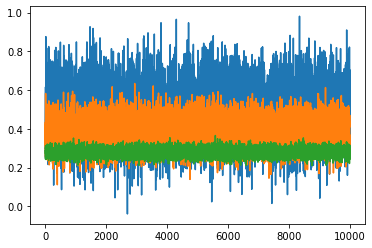

In [14]:
VasicekList = VasicekJPDF(10000)
plt.plot(VasicekList[0])
plt.plot(VasicekList[1])
plt.plot(VasicekList[2])
plt.show()

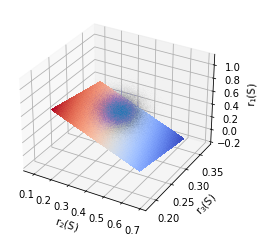

In [174]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

#ApproxEBVasicek3 = lambda x, y: coefVas3[1]*x+coefVas3[2]*y+coefVas3[0]
x = np.linspace(norm.ppf(1-0.9999, loc=EV2, scale=Var2),norm.ppf(0.9999, loc=EV2, scale=Var2), 1000)
y = np.linspace(norm.ppf(1-0.9999, loc=EV3, scale=Var3),norm.ppf(0.9999, loc=EV3, scale=Var3), 1000)
x, y = np.meshgrid(x, y)
z = EBVasicekPoints
ax.plot_surface(x, y, z, cmap=cm.coolwarm, linewidth=0, antialiased=False)

ax.scatter(VasicekList[1],VasicekList[2],VasicekList[0],s=0.0000001)

ax.set_xlabel('r$_2$(S)')
ax.set_ylabel('r$_3$(S)')
ax.set_zlabel('r$_1$(S)')

plt.show()

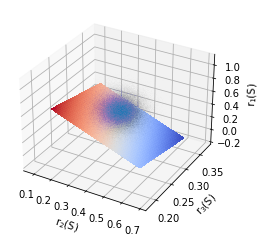

In [78]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

ApproxEBVasicek3 = lambda x, y: coefVas3[1]*x+coefVas3[2]*y+coefVas3[0]
x = np.linspace(norm.ppf(1-0.9999, loc=EV2, scale=Var2),norm.ppf(0.9999, loc=EV2, scale=Var2), 10000)
y = np.linspace(norm.ppf(1-0.9999, loc=EV3, scale=Var3),norm.ppf(0.9999, loc=EV3, scale=Var3), 10000)
x, y = np.meshgrid(x, y)
z = ApproxEBVasicek3(x,y)
ax.plot_surface(x, y, z, cmap=cm.coolwarm, linewidth=0, antialiased=False)

ax.scatter(VasicekList[1],VasicekList[2],VasicekList[0],s=0.0000001)

ax.set_xlabel('r$_2$(S)')
ax.set_ylabel('r$_3$(S)')
ax.set_zlabel('r$_1$(S)')

plt.show()

In [81]:
z

array([[ 0.63219431,  0.63214512,  0.63209593, ...,  0.14048022,
         0.14043104,  0.14038185],
       [ 0.63217363,  0.63212444,  0.63207525, ...,  0.14045954,
         0.14041035,  0.14036117],
       [ 0.63215294,  0.63210376,  0.63205457, ...,  0.14043886,
         0.14038967,  0.14034049],
       ...,
       [ 0.42544247,  0.42539328,  0.4253441 , ..., -0.06627162,
        -0.0663208 , -0.06636999],
       [ 0.42542179,  0.4253726 ,  0.42532341, ..., -0.0662923 ,
        -0.06634149, -0.06639067],
       [ 0.4254011 ,  0.42535192,  0.42530273, ..., -0.06631298,
        -0.06636217, -0.06641135]])

In [123]:
EBVasicek = lambda z : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*z+resultVasicek.y[2,1]*w1+resultVasicek.y[3,1]*w2)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*z+resultVasicek.y[2,2]*w1+resultVasicek.y[3,2]*w2)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*z+resultVasicek.y[2,3]*w1+resultVasicek.y[3,3]*w2)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*z+resultVasicek.y[2,4]*w1+resultVasicek.y[3,4]*w2)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*z+resultVasicek.y[2,5]*w1+resultVasicek.y[3,5]*w2)-1
x3 = np.linspace(norm.ppf(1-0.9999, loc=EV2, scale=Var2),norm.ppf(0.9999, loc=EV2, scale=Var2), 1000)
y3 = np.linspace(norm.ppf(1-0.9999, loc=EV3, scale=Var3),norm.ppf(0.9999, loc=EV3, scale=Var3), 1000)
x3, y3 = np.meshgrid(x3, y3)

DummyFunc = lambda x, y: 0*x+0*y+1

#z = ApproxEBVasicek3(x,y)

In [127]:
ApproxEBVasicek3 = lambda x, y: coefVas3[1]*x+coefVas3[2]*y+coefVas3[0]
x = np.linspace(norm.ppf(1-0.9999, loc=EV2, scale=Var2),norm.ppf(0.9999, loc=EV2, scale=Var2), 1000)
y = np.linspace(norm.ppf(1-0.9999, loc=EV3, scale=Var3),norm.ppf(0.9999, loc=EV3, scale=Var3), 1000)
x, y = np.meshgrid(x, y)
z = ApproxEBVasicek3(x,y)

In [108]:
# Warning: needs ~10 mins to compute

VasEB_init_guess = 0.2
EBVasicekPoints = DummyFunc(x3,y3)
for i in range(len(x3)):
    for j in range(len(y3)):
        w1 = x3[i,j]
        w2 = y3[i,j]
        sol = fsolve(EBVasicek, VasEB_init_guess)[0]
        EBVasicekPoints[i,j]=sol

In [137]:
Res3D = DummyFunc(x3,y3)
for i in range(len(x3)):
    for j in range(len(y3)):
        Res3D[i,j] = EBVasicekPoints[i,j]-z[i,j]

(0.2055995913542662, 0.35335790933378497)

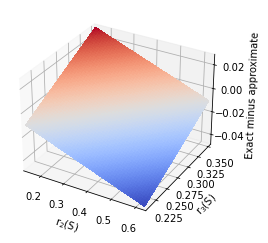

In [170]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

ax.plot_surface(x3, y3, Res3D, cmap=cm.coolwarm, linewidth=0, antialiased=False)
ax.set_xlabel('r$_2$(S)')
ax.set_ylabel('r$_3$(S)')
ax.set_zlabel('Exact minus approximate')
ax.set_xlim(norm.ppf(0.0001, loc=EV2, scale=Var2), norm.ppf(0.9999, loc=EV2, scale=Var2))
ax.set_ylim(norm.ppf(0.0001, loc=EV3, scale=Var3), norm.ppf(0.9999, loc=EV3, scale=Var3))